# Final models

Here I try two ensembles, a random forest and gradient boosting, and compare them with everything from notebooks 03 and 04. Then I pick my final model and a threshold for it. Like before, sections 1 to 4 only use the training set with the same 5 folds. The test set is only used once, in section 5, after everything is chosen.

In [1]:
# Add the project folder to the path so `from src import ...` works when this
# notebook is run from the notebooks folder.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict

from src.baselines import SCORING
from src.clean import clean
from src.evaluation import make_cv, split_by_lifter
from src.features import FEATURES, build_features
from src.models import (GB_GRID, RF_GRID, make_decision_tree, make_gradient_boosting,
                        make_logistic_regression, make_random_forest, tune)
from src.paths import INTERIM, REPORTS

cohort = pd.read_csv(INTERIM / 'audit_cohort.csv.gz', dtype=str, keep_default_na=False)
cleaned, _ = clean(cohort)
table = build_features(cleaned)

# I only keep the training side here. The test set is only used once, in section 5
# at the end, after I've chosen my final model and threshold.
train, _ = split_by_lifter(table)
X_train, y_train, groups_train = train[FEATURES], train['made'], train['Name']
print('training rows:', len(X_train))

training rows: 369880


## 1. Ensembles

In [2]:
start = time.perf_counter()
rf_search = tune(make_random_forest(), RF_GRID, X_train, y_train, groups_train)
print(f'random forest took {time.perf_counter() - start:.0f} seconds')
print('best settings:', rf_search.best_params_)

# Mean and std of balanced accuracy across the 5 folds for each setting I tried.
rf_table = pd.DataFrame({
    'max_depth': rf_search.cv_results_['param_model__max_depth'],
    'min_samples_leaf': rf_search.cv_results_['param_model__min_samples_leaf'],
    'balanced_accuracy_mean': rf_search.cv_results_['mean_test_balanced_accuracy'],
    'balanced_accuracy_std': rf_search.cv_results_['std_test_balanced_accuracy'],
}).round(4)
rf_table

random forest took 321 seconds
best settings: {'model__max_depth': 15, 'model__min_samples_leaf': 50}


,max_depth,min_samples_leaf,balanced_accuracy_mean,balanced_accuracy_std
0,10,50,0.6205,0.0017
1,10,200,0.6201,0.0020
2,15,50,0.6206,0.0016
3,15,200,0.6206,0.0017


In [3]:
start = time.perf_counter()
gb_search = tune(make_gradient_boosting(), GB_GRID, X_train, y_train, groups_train)
print(f'gradient boosting took {time.perf_counter() - start:.0f} seconds')
print('best settings:', gb_search.best_params_)

gb_table = pd.DataFrame({
    'learning_rate': gb_search.cv_results_['param_model__learning_rate'],
    'max_leaf_nodes': gb_search.cv_results_['param_model__max_leaf_nodes'],
    'min_samples_leaf': gb_search.cv_results_['param_model__min_samples_leaf'],
    'balanced_accuracy_mean': gb_search.cv_results_['mean_test_balanced_accuracy'],
    'balanced_accuracy_std': gb_search.cv_results_['std_test_balanced_accuracy'],
}).round(4)
gb_table

gradient boosting took 143 seconds
best settings: {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 200}


,learning_rate,max_leaf_nodes,min_samples_leaf,balanced_accuracy_mean,balanced_accuracy_std
0,0.05,31,50,0.6212,0.0012
1,0.05,31,200,0.6216,0.0011
2,0.05,63,50,0.6214,0.0016
3,0.05,63,200,0.6214,0.0014
4,0.10,31,50,0.6214,0.0011
5,0.10,31,200,0.6211,0.0014
6,0.10,63,50,0.6209,0.0015
7,0.10,63,200,0.6213,0.0014


## What the ensembles found

The random forest took 243 seconds to tune and gradient boosting took 127 seconds, so the forest took about twice as long even though it had 4 settings to try and gradient boosting had 8. For the forest, the best setting was a max depth of 15 with a minimum leaf size of 50, at 0.6206 balanced accuracy, and all four settings landed between 0.6201 and 0.6206. For gradient boosting, the best was a learning rate of 0.05, 31 leaves per tree and a minimum leaf size of 200, at 0.6216, and all eight settings landed between 0.6209 and 0.6216. So like with logistic regression in notebook 04, the settings I tried made very little difference. The gaps between settings are all smaller than the fold std (0.0011 to 0.0020).

## 2. All models compared

In [4]:
def best_row(search):
    """The fold scores for the setting each search picked, with the same column names
    as model_results.csv."""
    i = search.best_index_
    row = {}
    for metric in SCORING:
        row[f'{metric}_mean'] = search.cv_results_[f'mean_test_{metric}'][i]
        row[f'{metric}_std'] = search.cv_results_[f'std_test_{metric}'][i]
    return row

# The baselines, logistic regression and the tree come from notebook 04.
model_results = pd.read_csv(REPORTS / 'model_results.csv', index_col=0)
ensembles = pd.DataFrame({'random forest': best_row(rf_search),
                          'gradient boosting': best_row(gb_search)}).T
final_results = pd.concat([model_results, ensembles])[model_results.columns].round(4)
final_results.index.name = 'model'
final_results.to_csv(REPORTS / 'final_cv_results.csv')

# The scores I care about most go first.
first = [f'{m}_{s}' for m in ['balanced_accuracy', 'roc_auc', 'accuracy', 'recall_missed']
         for s in ['mean', 'std']]
final_results[first + [c for c in final_results.columns if c not in first]]

,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,recall_missed_mean,recall_missed_std,precision_made_mean,precision_made_std,recall_made_mean,recall_made_std,f1_made_mean,f1_made_std,precision_missed_mean,precision_missed_std,f1_missed_mean,f1_missed_std
model,,,,,,,,,,,,,,,,,,
always made,0.5000,0.0000,0.5000,0.0000,0.6102,0.0000,0.0000,0.0000,0.6102,0.0000,1.0000,0.0000,0.7579,0.0000,0.0000,0.0000,0.0000,0.0000
second-attempt rule,0.5553,0.0010,0.5553,0.0010,0.6383,0.0008,0.1792,0.0022,0.6399,0.0006,0.9315,0.0008,0.7586,0.0004,0.6256,0.0030,0.2785,0.0029
logistic regression,0.6113,0.0015,0.6562,0.0019,0.6209,0.0016,0.5680,0.0029,0.7035,0.0013,0.6546,0.0026,0.6782,0.0016,0.5123,0.0018,0.5387,0.0019
decision tree,0.6174,0.0016,0.6629,0.0022,0.6213,0.0036,0.6000,0.0122,0.7131,0.0024,0.6349,0.0132,0.6716,0.0066,0.5122,0.0042,0.5525,0.0033
random forest,0.6206,0.0016,0.6693,0.0019,0.6246,0.0017,0.6023,0.0023,0.7155,0.0013,0.6389,0.0027,0.6750,0.0019,0.5158,0.0019,0.5557,0.0017
gradient boosting,0.6216,0.0011,0.6701,0.0020,0.6249,0.0017,0.6068,0.0024,0.7170,0.0007,0.6364,0.0039,0.6743,0.0023,0.5160,0.0019,0.5577,0.0009


## 3. Choosing the final model

In [5]:
ranked = final_results.sort_values('balanced_accuracy_mean', ascending=False)
best_name, next_name = ranked.index[:2]
best, runner_up = ranked.loc[best_name], ranked.loc[next_name]
gap = best.balanced_accuracy_mean - runner_up.balanced_accuracy_mean
print('best model:', best_name, round(best.balanced_accuracy_mean, 4),
      'std', round(best.balanced_accuracy_std, 4))
print('next model:', next_name, round(runner_up.balanced_accuracy_mean, 4),
      'std', round(runner_up.balanced_accuracy_std, 4))
print('gap:', round(gap, 4))
print('gap bigger than both fold stds:',
      gap > max(best.balanced_accuracy_std, runner_up.balanced_accuracy_std))

best model: gradient boosting 0.6216 std 0.0011
next model: random forest 0.6206 std 0.0016
gap: 0.001
gap bigger than both fold stds: False


## Which model I picked

Gradient boosting has the highest mean balanced accuracy, 0.6216 (std 0.0011), so it's my final model. But the random forest is only 0.0010 behind at 0.6206 (std 0.0016), and that gap is smaller than the fold std of either model. So I can't honestly say gradient boosting is better than the forest. On these folds they do about the same. Gradient boosting is also a little ahead on ROC-AUC (0.6701 against 0.6693) and recall on misses (0.6068 against 0.6023), but those gaps are small too.

Neither ensemble is easy to explain, because both are made of many trees. The forest is a bit simpler: it's the average of 100 trees grown separately, while in gradient boosting each tree depends on the ones before it. The simplest model of all is still the single decision tree from notebook 04, which is 0.0042 behind gradient boosting at 0.6174. That gap is bigger than the fold std of either model, so the ensembles are a real but small step up from the tree. I'm keeping gradient boosting because my rule was to pick the highest mean.

## 4. Choosing a threshold

In [6]:
# A fresh copy of each model with the settings its search picked. Logistic regression and
# the tree use the settings notebook 04 picked.
final_models = {'logistic regression': make_logistic_regression(C=10),
                'decision tree': make_decision_tree(max_depth=8, min_samples_leaf=50),
                'random forest': rf_search.best_estimator_,
                'gradient boosting': gb_search.best_estimator_}

# Every training row is predicted by a copy of the model fitted on the other 4 folds,
# so the lifter in that row was never seen in training.
start = time.perf_counter()
oof_prob = cross_val_predict(final_models[best_name], X_train, y_train, groups=groups_train,
                             cv=make_cv(), method='predict_proba', n_jobs=-1)[:, 1]
print(f'out-of-fold probabilities took {time.perf_counter() - start:.0f} seconds')

# A lift is called made if its probability is at least the threshold.
made, missed = y_train.to_numpy() == 1, y_train.to_numpy() == 0
rows = []
for threshold in np.round(np.arange(0.30, 0.701, 0.01), 2):
    predicted_made = oof_prob >= threshold
    recall_made = predicted_made[made].mean()
    recall_missed = (~predicted_made)[missed].mean()
    rows.append({'threshold': threshold, 'balanced_accuracy': (recall_made + recall_missed) / 2,
                 'recall_missed': recall_missed, 'recall_made': recall_made})
thresholds = pd.DataFrame(rows).set_index('threshold')

best_threshold = thresholds.balanced_accuracy.idxmax()
print('best threshold:', best_threshold)
print('balanced accuracy at 0.5:', round(thresholds.balanced_accuracy[0.5], 4))
print('balanced accuracy at the best threshold:',
      round(thresholds.balanced_accuracy[best_threshold], 4))
# The thresholds just around the best one.
thresholds.loc[best_threshold - 0.05:best_threshold + 0.05].round(4)

out-of-fold probabilities took 30 seconds
best threshold: 0.5
balanced accuracy at 0.5: 0.6216
balanced accuracy at the best threshold: 0.6216


,balanced_accuracy,recall_missed,recall_made
threshold,,,
0.45,0.6145,0.4705,0.7584
0.46,0.6168,0.4985,0.7352
0.47,0.6187,0.5249,0.7126
0.48,0.6201,0.5520,0.6882
0.49,0.6208,0.5788,0.6629
0.50,0.6216,0.6068,0.6364
0.51,0.6212,0.6324,0.6099
0.52,0.6206,0.6583,0.5829
0.53,0.6189,0.6820,0.5559


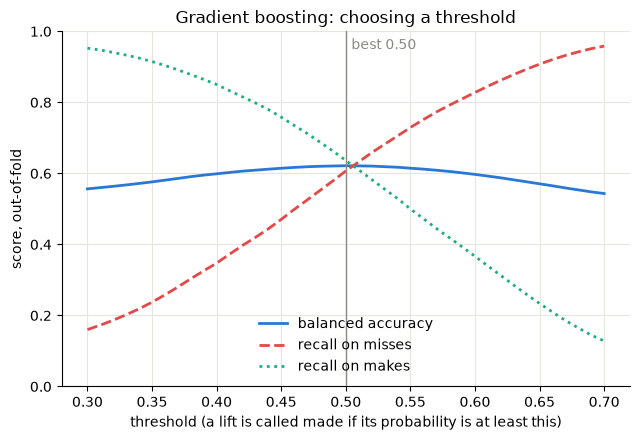

In [7]:
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(exist_ok=True)

# The same colours and look as the figures in notebook 04.
BLUE, ORANGE, AQUA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True})

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(thresholds.index, thresholds.balanced_accuracy, color=BLUE, linewidth=2,
        label='balanced accuracy')
ax.plot(thresholds.index, thresholds.recall_missed, color=RED, linestyle='--', linewidth=2,
        label='recall on misses')
ax.plot(thresholds.index, thresholds.recall_made, color=AQUA, linestyle=':', linewidth=2,
        label='recall on makes')
ax.axvline(best_threshold, color=GREY, linewidth=1)
ax.annotate(f'best {best_threshold:.2f}', (best_threshold, 0.95), xytext=(4, 0),
            textcoords='offset points', color=GREY)
ax.set_ylim(0, 1)
ax.set_xlabel('threshold (a lift is called made if its probability is at least this)')
ax.set_ylabel('score, out-of-fold')
ax.set_title(f'{best_name.capitalize()}: choosing a threshold')
ax.legend(loc='lower center', frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'threshold.png', dpi=150)
plt.show()

## The threshold trade-off

The model gives every lift a probability of being made, and the threshold is the cut-off. A lift is called made if its probability is at least the threshold, so a higher threshold calls more lifts a miss. That catches more of the real misses but wrongly flags more of the makes. Going from 0.45 to 0.55, recall on misses goes up from 0.4705 to 0.7293, and recall on makes drops from 0.7584 to 0.5000.

The best out-of-fold balanced accuracy was at 0.50, the default, with 0.6216. So moving the threshold gained nothing here. I expected any gain to be small, because class_weight='balanced' already makes each missed lift count for more during training, which pushes the best threshold close to 0.5. The curve is also flat near the top: everything from 0.48 to 0.52 is within 0.0015 of the best. I'll keep 0.50 for my final model.

## 5. Final check on the test set

I'm writing this before running any of the code below. My final model is gradient boosting with a learning rate of 0.05, 31 leaves per tree and a minimum leaf size of 200, and I'm leaving the threshold at 0.50. I chose all of that on the training folds only, using the rule I set before tuning: pick the highest mean CV balanced accuracy. The random forest was tied with it within the fold std, so I score it on the test set too, but only to compare. It doesn't change my choice. This is the only time I use the test set.

In [8]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, get_scorer, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline

from src.baselines import SecondAttemptRule, make_preprocessor

# This is the first and only time I take the test side of the split.
train_again, test = split_by_lifter(table)
assert train_again.equals(train), 'The split should be the same as at the top'
assert not set(train.Name) & set(test.Name), 'A lifter appears in both train and test'
X_test, y_test = test[FEATURES], test['made']
print('test rows:', len(X_test))

# The settings the searches picked: logistic regression and the tree from notebook 04,
# the forest and gradient boosting from section 1. clone() gives an unfitted copy, so
# each model is fitted once on the whole training set, with no new tuning.
test_models = {
    'always made': Pipeline([('prep', make_preprocessor()),
                             ('model', DummyClassifier(strategy='most_frequent'))]),
    'second-attempt rule': SecondAttemptRule(),
    'logistic regression': final_models['logistic regression'],
    'decision tree': final_models['decision tree'],
    'random forest': final_models['random forest'],
    'gradient boosting': final_models['gradient boosting'],
}
assert best_name == 'gradient boosting', 'The markdown above says gradient boosting'

start = time.perf_counter()
fitted = {name: clone(model).fit(X_train, y_train) for name, model in test_models.items()}
print(f'fitting all six on the training set took {time.perf_counter() - start:.0f} seconds')

final_model = fitted[best_name]
settings = final_model['model'].get_params()
print('final model settings:',
      {k: settings[k] for k in ['learning_rate', 'max_leaf_nodes', 'min_samples_leaf']})

test rows: 91948


fitting all six on the training set took 22 seconds
final model settings: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 200}


In [9]:
# The same scores as SCORING, but on the test set. Every model uses its normal predict,
# which is the 0.50 threshold.
test_scores = {name: {metric: get_scorer(scorer)(model, X_test, y_test)
                      for metric, scorer in SCORING.items()}
               for name, model in fitted.items()}
test_results = pd.DataFrame(test_scores).T.round(4)
test_results.index.name = 'model'
test_results.to_csv(REPORTS / 'test_results.csv')
test_results

,balanced_accuracy,accuracy,roc_auc,precision_made,recall_made,f1_made,precision_missed,recall_missed,f1_missed
model,,,,,,,,,
always made,0.5000,0.6069,0.5000,0.6069,1.0000,0.7554,0.0000,0.0000,0.0000
second-attempt rule,0.5557,0.6362,0.5557,0.6368,0.9323,0.7567,0.6314,0.1791,0.2790
logistic regression,0.6116,0.6210,0.6560,0.7006,0.6558,0.6775,0.5164,0.5673,0.5406
decision tree,0.6183,0.6178,0.6638,0.7149,0.6159,0.6617,0.5114,0.6207,0.5608
random forest,0.6222,0.6259,0.6699,0.7142,0.6396,0.6748,0.5208,0.6048,0.5597
gradient boosting,0.6220,0.6251,0.6706,0.7146,0.6365,0.6733,0.5198,0.6076,0.5603


In [10]:
# CV balanced accuracy from section 2 next to the test balanced accuracy.
cv_results = pd.read_csv(REPORTS / 'final_cv_results.csv', index_col=0)
comparison = pd.DataFrame({'cv_balanced_accuracy': cv_results.balanced_accuracy_mean,
                           'cv_std': cv_results.balanced_accuracy_std,
                           'test_balanced_accuracy': test_results.balanced_accuracy})
comparison['difference'] = comparison.test_balanced_accuracy - comparison.cv_balanced_accuracy
comparison.round(4)

,cv_balanced_accuracy,cv_std,test_balanced_accuracy,difference
model,,,,
always made,0.5000,0.0000,0.5000,0.0000
second-attempt rule,0.5553,0.0010,0.5557,0.0004
logistic regression,0.6113,0.0015,0.6116,0.0003
decision tree,0.6174,0.0016,0.6183,0.0009
random forest,0.6206,0.0016,0.6222,0.0016
gradient boosting,0.6216,0.0011,0.6220,0.0004


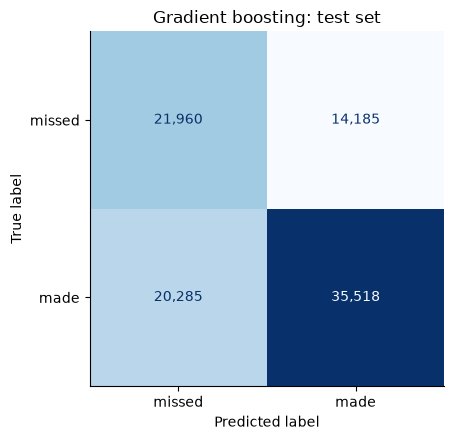

In [11]:
# I keep the final model's test predictions so the next section can reuse them.
final_test_pred = final_model.predict(X_test)
final_test_prob = final_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_test_pred, labels=[0, 1],
                                        display_labels=['missed', 'made'], cmap='Blues',
                                        colorbar=False, values_format=',d', ax=ax)
ax.grid(False)
ax.set_title(f'{best_name.capitalize()}: test set')
fig.tight_layout()
fig.savefig(FIGURES / 'test_confusion_matrix.png', dpi=150)
plt.show()

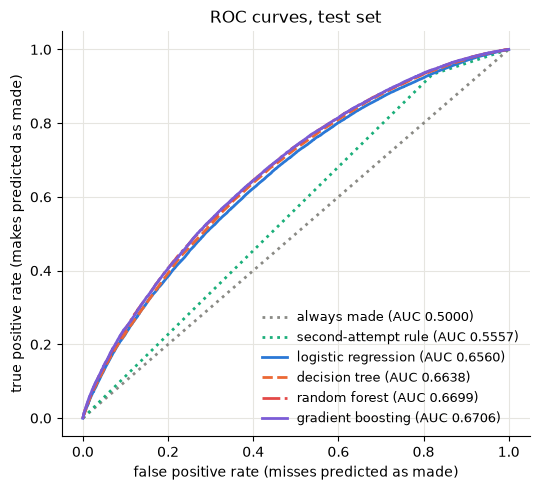

In [12]:
# Always made gives every lift the same probability, so its curve is the diagonal.
PURPLE = '#7b5cd6'
styles = {'always made': (GREY, ':'), 'second-attempt rule': (AQUA, ':'),
          'logistic regression': (BLUE, '-'), 'decision tree': (ORANGE, '--'),
          'random forest': (RED, '-.'), 'gradient boosting': (PURPLE, '-')}
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, model in fitted.items():
    prob = final_test_prob if name == best_name else model.predict_proba(X_test)[:, 1]
    false_pos, true_pos, _ = roc_curve(y_test, prob)
    colour, line = styles[name]
    ax.plot(false_pos, true_pos, color=colour, linestyle=line, linewidth=2,
            label=f'{name} (AUC {roc_auc_score(y_test, prob):.4f})')
ax.set_xlabel('false positive rate (misses predicted as made)')
ax.set_ylabel('true positive rate (makes predicted as made)')
ax.set_title('ROC curves, test set')
ax.legend(loc='lower right', frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / 'test_roc_curves.png', dpi=150)
plt.show()

## How the test score compares

The test scores are very close to the CV scores. Gradient boosting got 0.6220 balanced accuracy on the test set against 0.6216 in CV, a difference of 0.0004, which is smaller than its fold std of 0.0011. Every model is within 0.0016 of its CV score, and the order of the models is almost the same, so the grouped split and the 5 folds look like they gave me an honest estimate. On the test set the final model caught 21,960 of the 36,145 missed lifts (recall 0.6076), but it also wrongly called 20,285 of the 55,803 made lifts a miss.

The CV score of the setting I picked could be very slightly too high, because it was the best of several settings and some of that lead could be luck. The test set is the fair check, since nothing was chosen on it. Here every model scored the same or a tiny bit higher on the test set than in CV, so I don't see any sign of that.

The random forest and gradient boosting are still tied. The forest is 0.0002 ahead on test balanced accuracy (0.6222 against 0.6220), and gradient boosting is 0.0007 ahead on ROC-AUC (0.6706 against 0.6699). Both gaps are smaller than the fold std, so neither model is clearly better. I'm sticking with gradient boosting because I chose it before looking at the test set.

## 6. What the final model relies on

took 3 seconds


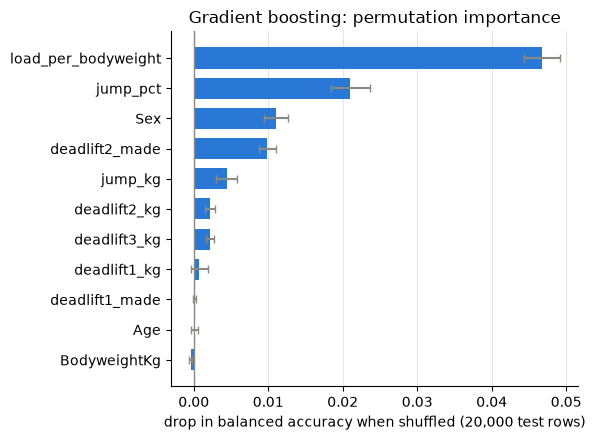

,mean_drop,std
load_per_bodyweight,0.0468,0.0024
jump_pct,0.0210,0.0026
Sex,0.0110,0.0017
deadlift2_made,0.0099,0.0011
jump_kg,0.0044,0.0014
deadlift2_kg,0.0022,0.0007
deadlift3_kg,0.0022,0.0006
deadlift1_kg,0.0007,0.0011
deadlift1_made,0.0001,0.0002
Age,0.0001,0.0005


In [13]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score, recall_score

from src.evaluation import SEED

# I shuffle one input column at a time and see how much balanced accuracy drops. A big
# drop means the model leans on that input. I use a random 20,000 of the test rows to
# keep it quick, and final_model as it is, with nothing refitted.
sample = X_test.sample(20000, random_state=SEED)
start = time.perf_counter()
perm = permutation_importance(final_model, sample, y_test.loc[sample.index],
                              scoring='balanced_accuracy', n_repeats=5, random_state=SEED)
print(f'took {time.perf_counter() - start:.0f} seconds')
perm_importance = pd.DataFrame({'mean_drop': perm.importances_mean,
                                'std': perm.importances_std},
                               index=FEATURES).sort_values('mean_drop')

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(perm_importance.index, perm_importance.mean_drop, xerr=perm_importance['std'],
        color=BLUE, height=0.7, error_kw={'ecolor': GREY, 'capsize': 3})
ax.axvline(0, color=GREY, linewidth=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('drop in balanced accuracy when shuffled (20,000 test rows)')
ax.set_title('Gradient boosting: permutation importance')
fig.tight_layout()
fig.savefig(FIGURES / 'permutation_importance.png', dpi=150)
plt.show()
perm_importance.sort_values('mean_drop', ascending=False).round(4)

## What the importance shows

Shuffling load_per_bodyweight drops balanced accuracy the most, by 0.0468, so that's the input the model leans on hardest. Next come jump_pct (0.0210), Sex (0.0110) and whether the second attempt was made (0.0099). After that the drops are small, and for deadlift1_made, Age and BodyweightKg they're about zero (0.0001, 0.0001 and -0.0004), so shuffling them makes no real difference.

This mostly matches the decision tree's feature importance in notebook 04. There, load_per_bodyweight (0.3761) and deadlift2_made (0.3195) were the top two by a long way, and jump_pct was third (0.0793). The biggest difference is Sex. In the tree it was split into Sex_M (0.0162) and Sex_F (0.0124) and both were low down, but here it's third. The two aren't measured the same way, though. The tree's importance comes from how much each split helped during training, and permutation importance is how much the score drops on rows the model never saw. So I only compare the order, not the sizes. One reason BodyweightKg could look useless is that load_per_bodyweight already has bodyweight built into it, so shuffling one still leaves the other.

deadlift2_made also ranks lower here (4th) than in the tree, where it was 2nd. My likely explanation is that jump_pct and the attempt weights carry a lot of the same information. A lifter who misses their second attempt often repeats the same weight, so their jump is close to zero. That means when one of these inputs is shuffled, the model can still lean on the others. I haven't proved this, it's just my best guess from how the inputs are built.

## 7. Does it work the same for everyone?

In [14]:
def group_scores(actual, predicted):
    return {'rows': len(actual), 'success_rate': actual.mean(),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'recall_missed': recall_score(actual, predicted, pos_label=0, zero_division=0),
            'recall_made': recall_score(actual, predicted, pos_label=1, zero_division=0)}


# The same age bands as the error analysis in notebook 04.
age_band = pd.cut(test.Age, [-np.inf, 18, 24, 40, np.inf], right=False,
                  labels=['<18', '18-23', '24-39', '40+'])
breakdowns = {'sex': test.Sex,
              'age': age_band.cat.add_categories('missing').fillna('missing')}

# I leave out any group with fewer than 30 test rows, because that's too few to judge.
MIN_ROWS = 30
test_preds = pd.DataFrame({'made': y_test, 'predicted': final_test_pred})
left_out = []
rows = [{'group': 'all rows', 'band': 'all', **group_scores(test_preds.made, test_preds.predicted)}]
for group, band in breakdowns.items():
    for value, part in test_preds.groupby(band, observed=True):
        if len(part) < MIN_ROWS:
            left_out.append(f'{group} {value} ({len(part)} rows)')
            continue
        rows.append({'group': group, 'band': str(value),
                     **group_scores(part.made, part.predicted)})

# Only counts and rates here, nothing about any single lifter.
print('left out, under 30 rows:', left_out)

test_by_group = pd.DataFrame(rows).round(4)
test_by_group.to_csv(REPORTS / 'test_by_group.csv', index=False)
test_by_group

left out, under 30 rows: ['sex Mx (1 rows)']


,group,band,rows,success_rate,balanced_accuracy,recall_missed,recall_made
0,all rows,all,91948,0.6069,0.6220,0.6076,0.6365
1,sex,F,31136,0.6575,0.5996,0.4074,0.7919
2,sex,M,60811,0.5810,0.6189,0.6913,0.5464
3,age,<18,9262,0.6288,0.6258,0.4997,0.7519
4,age,18-23,27343,0.5889,0.6176,0.6684,0.5669
5,age,24-39,29159,0.5917,0.6198,0.6505,0.5891
6,age,40+,11733,0.6310,0.6079,0.5313,0.6845
7,age,missing,14451,0.6380,0.6241,0.5129,0.7352


In [15]:
# The same groups from the CV error analysis in notebook 04, to compare. Those numbers
# are the decision tree's out-of-fold predictions on the training set, not this model.
cv_groups = pd.read_csv(REPORTS / 'error_analysis.csv')
cv_groups = cv_groups[cv_groups.group.isin(['all rows', 'sex', 'age'])].set_index(['group', 'band'])
side_by_side = (test_by_group.set_index(['group', 'band'])[['balanced_accuracy', 'recall_missed']]
                .join(cv_groups[['balanced_accuracy', 'recall_missed']], rsuffix='_cv_tree'))
side_by_side

balanced_accuracy  recall_missed  balanced_accuracy_cv_tree  \
group    band                                                                   
all rows all                 0.6220         0.6076                     0.6174   
sex      F                   0.5996         0.4074                     0.5952   
         M                   0.6189         0.6913                     0.6157   
age      <18                 0.6258         0.4997                     0.6101   
         18-23               0.6176         0.6684                     0.6097   
         24-39               0.6198         0.6505                     0.6153   
         40+                 0.6079         0.5313                     0.6089   
         missing             0.6241         0.5129                     0.6193   

                  recall_missed_cv_tree  
group    band                            
all rows all                     0.6000  
sex      F                       0.4199  
         M                       0.6747  
age      <18                     0.4479  
         18-23                   0.6540  
         24-39                   0.6726  
         40+                     0.4717  
         missing                 0.5209

## Gaps between groups

The biggest gap is between women and men. The model gets 0.5996 balanced accuracy for women against 0.6189 for men, but the bigger difference is in which mistakes it makes. It only catches 40.7% of women's missed lifts (recall 0.4074) against 69.1% for men (0.6913), and it goes the other way for made lifts (0.7919 for women, 0.5464 for men). Women make more of their third attempts in the test set (65.8% against 58.1%), so the model leans towards calling a woman's lift made. The age bands are closer on balanced accuracy (0.6079 to 0.6258), but under-18s, over-40s and lifters with no age recorded show the same pattern as women. They make more of their lifts (62.9%, 63.1% and 63.8%) and the model catches fewer of their misses (0.4997, 0.5313 and 0.5129). I left out any group with fewer than 30 test rows, since that's too few to judge. That only affected Mx, which had 1 row.

This matches the CV error analysis in notebook 04, which used the decision tree. There, recall on misses was 0.4199 for women and 0.6747 for men, and the under-18 and 40+ bands were also the lowest (0.4479 and 0.4717). So the gap isn't just a quirk of the test set or of gradient boosting.

It would matter if a coach relied on this. For a woman, the model says "made" for most of the lifts she ends up missing, so it would warn far less often for women than for men, even though the warning is the useful part.

## 8. Does it hold up over time?

In [16]:
year = test.Date.str[:4].astype(int)
print('test meet years:', year.min(), 'to', year.max())
year_band = pd.cut(year, [-np.inf, 2015, 2020, 2023, np.inf], right=False,
                   labels=['before 2015', '2015-2019', '2020-2022', '2023 onwards'])

rows = []
for value, part in test_preds.groupby(year_band, observed=True):
    rows.append({'years': str(value), 'rows': len(part), 'success_rate': part.made.mean(),
                 'balanced_accuracy': balanced_accuracy_score(part.made, part.predicted)})
test_by_year = pd.DataFrame(rows).round(4)
test_by_year.to_csv(REPORTS / 'test_by_year.csv', index=False)
test_by_year

test meet years: 1974 to 2026


,years,rows,success_rate,balanced_accuracy
0,before 2015,4078,0.5853,0.6195
1,2015-2019,32550,0.6218,0.6236
2,2020-2022,16284,0.6269,0.6212
3,2023 onwards,39036,0.5884,0.6184


## Over time

Balanced accuracy stays between 0.6184 and 0.6236 across the four year bands, so the model looks stable over time. The success rate moves a bit more, from 58.5% before 2015 up to 62.7% in 2020-2022 and back down to 58.8% from 2023 onwards, but the model's score barely changes with it. The before-2015 band is the smallest at 4,078 rows, so it's the least certain.

The test meets go from 1974 to 2026, but my split is by lifter, not by time. The training set wasn't limited to older meets, so the model may have learned from meets in the same years it's tested on. This is a check that it works across years, not a true test of predicting future meets. For that I'd need to train on older meets and test on newer ones.

## Conclusion

My final model is gradient boosting with a learning rate of 0.05, 31 leaves per tree and a minimum leaf size of 200, with the threshold left at 0.50. On the test set it got 0.6220 balanced accuracy, against 0.5557 for the second-attempt rule and 0.5000 for always guessing "made". It catches 60.8% of missed lifts (recall 0.6076), where the rule catches 17.9% (0.1791). Its plain accuracy is lower than the rule's, though (0.6251 against 0.6362), because it calls more made lifts a miss. The test score matched CV closely (0.6220 against 0.6216), so I trust the CV numbers I used to choose it. The random forest was tied with it in both CV and on the test set.

The model relies most on load_per_bodyweight, then jump_pct, Sex and whether the second attempt was made. Age, bodyweight and whether the first attempt was made add almost nothing on their own.

There are some clear limits. A balanced accuracy of 0.62 is a real step up from the baselines, but the model is still wrong a lot. On the test set it wrongly called 20,285 made lifts a miss. It also works worse for women than for men: it catches 40.7% of women's misses against 69.1% of men's. My inputs don't say anything about a lifter's earlier meets or how their squat and bench went on the day. The split is by lifter, not by time, so I haven't tested predicting future meets. And the ensembles are harder to explain than the single decision tree, which was close behind (0.6183 on the test set).

Next, I'd try adding inputs from each lifter's earlier meets, like how often they made their third deadlift before, and their squat and bench attempts from the same meet. I'd also test on a split by time, training on older meets and testing on the newest ones, to see if it really holds up on future meets. I'd also look again at the gap between women and men. A different threshold for each could even out how many misses get caught. But that means treating lifters differently because of their sex, which raises its own fairness questions, so it's something I'd want to look at carefully rather than just switch on. I'd also test a version of the model without Sex as an input at all. It came out as the 3rd most important input in section 6, so I'd want to see how much the scores change without it.

## Are the probabilities trustworthy?

This only describes the final model on the test set. Nothing is chosen from it: the model and the threshold were already fixed in sections 3 and 4.

Brier: model 0.227, constant 61% guess 0.239
mean predicted 0.509, actual make rate 0.607
   mean_predicted  share_made    gap
0           0.241       0.320  0.079
1           0.350       0.453  0.103
2           0.411       0.512  0.101
3           0.457       0.563  0.106
4           0.497       0.605  0.108
5           0.535       0.642  0.107
6           0.575       0.684  0.109
7           0.616       0.719  0.103
8           0.663       0.753  0.090
9           0.744       0.818  0.074


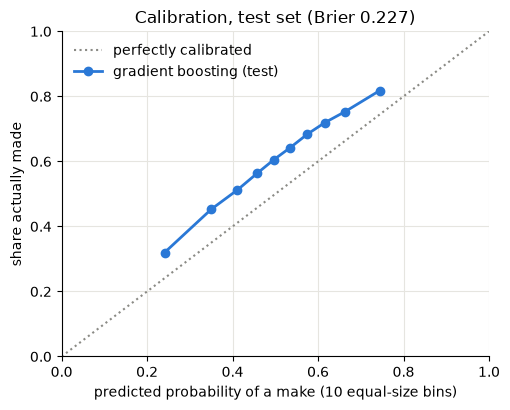

In [17]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

gb = fitted['gradient boosting']
p_test = gb.predict_proba(X_test)[:, 1]

brier_model = brier_score_loss(y_test, p_test)
brier_constant = brier_score_loss(y_test, np.full_like(p_test, y_train.mean()))
print(f'Brier: model {brier_model:.3f}, constant {y_train.mean():.0%} guess {brier_constant:.3f}')
print(f'mean predicted {p_test.mean():.3f}, actual make rate {y_test.mean():.3f}')

frac_made, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
calib = pd.DataFrame({'mean_predicted': mean_pred, 'share_made': frac_made}).round(3)
calib['gap'] = (calib.share_made - calib.mean_predicted).round(3)
print(calib)
calib.to_csv(REPORTS / 'test_calibration.csv', index=False)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, 1], [0, 1], color=GREY, linestyle=':', linewidth=1.5, label='perfectly calibrated')
ax.plot(mean_pred, frac_made, color=BLUE, marker='o', linewidth=2, label='gradient boosting (test)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('predicted probability of a make (10 equal-size bins)')
ax.set_ylabel('share actually made')
ax.set_title(f'Calibration, test set (Brier {brier_model:.3f})')
ax.legend(loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'calibration.png', dpi=150)
plt.show()